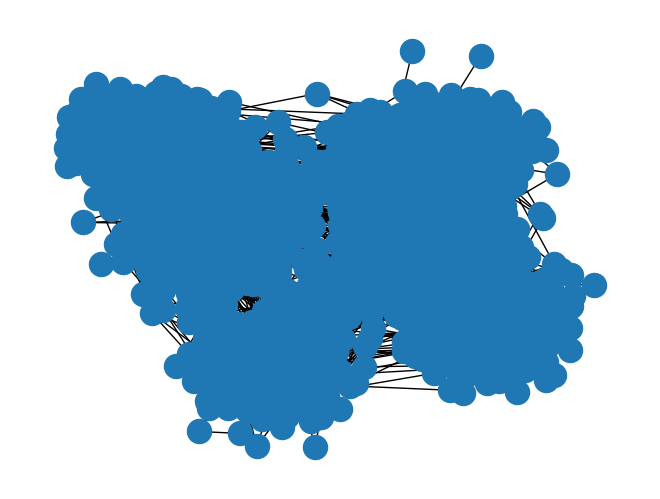

In [1]:
import pandas as pd
import networkx as nx

G = nx.read_edgelist("edges_train.edgelist", data=False, nodetype=int, delimiter=",")

pos = nx.spring_layout(G)

nx.draw(G, pos=pos)

In [2]:
N = len(list(G.nodes()))
print(f"Number of nodes: {N}")

E = len(list(G.edges()))
print(f"Number of edges: {E}")

Number of nodes: 1800
Number of edges: 6377


In [3]:
# Add categorical attributes of nodes from attributes.csv
df = pd.read_csv("attributes.csv")
for index, row in df.iterrows():
    G.nodes[row["ID"]]["attribute"] = row["attribute"]

# Quick check
print(f"Node 0 attribute: {G.nodes[1]['attribute']}")
print(f"Total nodes with attribute: {len(nx.get_node_attributes(G, 'attribute'))}")


Node 0 attribute: f
Total nodes with attribute: 1800


In [4]:
# Detect communities (from Lab 5) and compute individual node homophily
from networkx.algorithms.community import greedy_modularity_communities

# 1. Community detection
communities = list(greedy_modularity_communities(G))
node_community = {}
for cid, comm in enumerate(communities):
    for node in comm:
        node_community[node] = cid
nx.set_node_attributes(G, node_community, "community")

# 2. Node homophily ratio (percentage of a node's friends sharing its attribute)
node_homophily = {}
for n in G.nodes():
    neighbors = list(G.neighbors(n))
    if not neighbors:
        node_homophily[n] = 0.0
    else:
        attr_n = G.nodes[n]["attribute"]
        node_homophily[n] = sum(1 for w in neighbors if G.nodes[w]["attribute"] == attr_n) / len(neighbors)
nx.set_node_attributes(G, node_homophily, "homophily")

print(f"Detected {len(communities)} communities.")
print(f"Node 0: attribute={G.nodes[0]['attribute']}, community={G.nodes[0]['community']}, homophily={G.nodes[0]['homophily']:.2f}")


Detected 6 communities.
Node 0: attribute=f, community=4, homophily=0.60


### Feature Engineering

For each node pair $(u, v)$, we compute 9 features across three complementary groups:
- **Topology**: Common Neighbors, Jaccard Coefficient, Resource Allocation, Adamic-Adar, and Preferential Attachment.
- **Community**: `same_community` (whether $u$ and $v$ belong to the same detected cluster).
- **Node Attributes & Homophily**: `same_attribute` (matching category), `same_attr_common_neighbors` (in-group mutual friends), and `endpoint_homophily` (average in-group friend ratio).


In [5]:
# Feature extraction function for a pair of nodes (u, v)
def get_features(G, u, v):
    # 1. Topological / neighborhood features
    cn = len(list(nx.common_neighbors(G, u, v)))
    jc = next(nx.jaccard_coefficient(G, [(u, v)]))[2]
    ra = next(nx.resource_allocation_index(G, [(u, v)]))[2]
    aa = next(nx.adamic_adar_index(G, [(u, v)]))[2]
    pa = next(nx.preferential_attachment(G, [(u, v)]))[2]
    
    # 2. Attribute & community features
    attr_u = G.nodes[u]["attribute"]
    attr_v = G.nodes[v]["attribute"]
    same_attr = 1 if attr_u == attr_v else 0
    same_comm = 1 if G.nodes[u]["community"] == G.nodes[v]["community"] else 0
    
    # 3. In-group mutual friends (shared friends who also have the same attribute)
    if same_attr == 1 and cn > 0:
        same_attr_cn = sum(1 for z in nx.common_neighbors(G, u, v) if G.nodes[z]["attribute"] == attr_u)
    else:
        same_attr_cn = 0
        
    # 4. Average endpoint homophily ratio
    homophily = (G.nodes[u]["homophily"] + G.nodes[v]["homophily"]) / 2.0
    
    return [cn, jc, ra, aa, pa, same_attr, same_comm, same_attr_cn, homophily]

feature_names = [
    "common_neighbors", "jaccard_coeff", "resource_allocation", "adamic_adar",
    "pref_attachment", "same_attribute", "same_community", "same_attr_common_neighbors", "endpoint_homophily"
]

# Test on an existing edge
u, v = list(G.edges())[0]
print(f"Features for edge ({u}, {v}):")
for name, val in zip(feature_names, get_features(G, u, v)):
    print(f"  {name}: {val}")


Features for edge (0, 49):
  common_neighbors: 0
  jaccard_coeff: 0.0
  resource_allocation: 0
  adamic_adar: 0
  pref_attachment: 185
  same_attribute: 0
  same_community: 1
  same_attr_common_neighbors: 0
  endpoint_homophily: 0.327027027027027


In [6]:
import numpy as np
from sklearn.model_selection import train_test_split

# Create balanced dataset (1:1 ratio: 6377 positive edges, 6377 negative non-edges)
np.random.seed(42)
X = []
y = []

# 1. Positive examples (existing edges in G)
for u, v in G.edges():
    X.append(get_features(G, u, v))
    y.append(1)

# 2. Negative examples (random non-existent edges)
neg_edges = set()
n_nodes = len(G.nodes())

while len(neg_edges) < len(G.edges()):
    u = np.random.randint(0, n_nodes)
    v = np.random.randint(0, n_nodes)
    if u != v and not G.has_edge(u, v):
        edge = (min(u, v), max(u, v))
        if edge not in neg_edges:
            neg_edges.add(edge)
            X.append(get_features(G, u, v))
            y.append(0)

X = np.array(X)
y = np.array(y)

# Local train/validation split (80% train, 20% validation for testing locally)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Total dataset: {len(y)} samples ({sum(y == 1)} positive, {sum(y == 0)} negative)")
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")


Total dataset: 12754 samples (6377 positive, 6377 negative)
X_train shape: (10203, 9), X_test shape: (2551, 9)
